In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

In [ ]:
# Set color scheme
plt.style.use("tableau-colorblind10")

# Set ticks
plt.rc("xtick", bottom=True, top=True, direction="in")
plt.rc("ytick", left=True, right=True, direction="in")
plt.rc("xtick.minor", visible=True)
plt.rc("ytick.minor", visible=True)

In [ ]:
from np_match.debye import get_all_from_iq_int
from np_match.workflow.fitting import ScatteringData, load_experimental_data

In [ ]:
from functools import cache
from math import ceil

import numpy as np
import pandas as pd
import torch
from ase.io import read
from matplotlib.axes import Axes

In [ ]:
exp_data = load_experimental_data("../../../data/experimental_scattering.h5")

Disregarding key: meta


In [5]:
data = {k: v for k, v in np.load("../fits/fit.npz").items()}

In [6]:
{k: v.shape for k, v in data.items()}

{'iq_int': (3655, 2279),
 'xscale': (3655, 92),
 'yscale': (3655, 92),
 'biso': (3655, 92),
 'mse_fq': (3655, 92),
 'rwp_fq': (3655, 92),
 'family': (3655, 92),
 'wulff': (3655, 92),
 'size': (3655, 92),
 'max_miller': (3655, 92),
 'twin_111_ratio': (3655, 92),
 'sim_idx': (3655, 92),
 'exp_sample': (3655, 92),
 'q': (2279,),
 'q_ref': (2067,),
 'form_avg_sq': (2279,)}

In [7]:
np.setdiff1d(np.arange(3655), data["sim_idx"][:, 0])

array([], dtype=int64)

In [8]:
num_sim, num_exp = data["yscale"].shape

In [9]:
keys = set(data.keys())
keys.remove("q")
keys.remove("q_ref")
keys.remove("iq_int")
keys.remove("form_avg_sq")
broadcast_shape = data["yscale"].shape
data_for_pd = {k: data[k].flat for k in keys}
df = pd.DataFrame(data_for_pd)
df

,mse_fq,rwp_fq,exp_sample,yscale,size,family,wulff,xscale,sim_idx,biso,twin_111_ratio,max_miller
0,0.029252,0.959080,1,0.082827,55,oct,True,1.084687,0,0.0,NaN,1.0
1,0.048796,0.997394,2,-0.024809,55,oct,True,1.050661,0,0.0,NaN,1.0
2,0.064732,0.941507,3,0.135730,55,oct,True,1.025528,0,0.0,NaN,1.0
3,0.038053,0.932576,4,0.111776,55,oct,True,1.021436,0,0.0,NaN,1.0
4,0.044106,0.940015,5,0.113815,55,oct,True,1.026699,0,0.0,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
336255,0.017222,0.641328,88,0.059400,49901,sph,False,0.977009,3654,0.0,NaN,NaN
336256,0.041651,0.885779,89,0.040458,49901,sph,False,0.977037,3654,0.0,NaN,NaN
336257,0.045821,0.868378,90,0.046351,49901,sph,False,0.978390,3654,0.0,NaN,NaN
336258,0.027190,0.742303,91,0.056554,49901,sph,False,0.979144,3654,0.0,NaN,NaN


In [10]:
assert df["sim_idx"].unique().size == df["sim_idx"].max() + 1
assert len(df) == (df["sim_idx"].max() + 1) * df["exp_sample"].max()

[Text(0.5, 0, 'biso')]

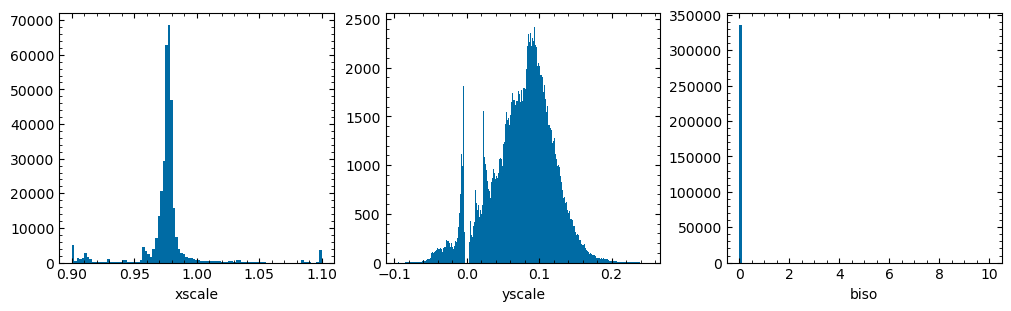

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
axs[0].hist(
    data["xscale"].flatten(), bins=np.linspace(0.9 - 1e-6, 1.1 + 1e-6, 100)
)
axs[0].set(xlabel="xscale")
axs[1].hist(data["yscale"].flatten(), bins="sqrt")
axs[1].set(xlabel="yscale")
axs[2].hist(
    data["biso"].flatten(), bins=np.linspace(0.0 - 1e-6, 10.0 + 1e-6, 100)
)
axs[2].set(xlabel="biso")

In [16]:
data["size"].max()

49990

[Text(0.5, 0, 'Number of atoms'), Text(0, 0.5, 'Counts')]

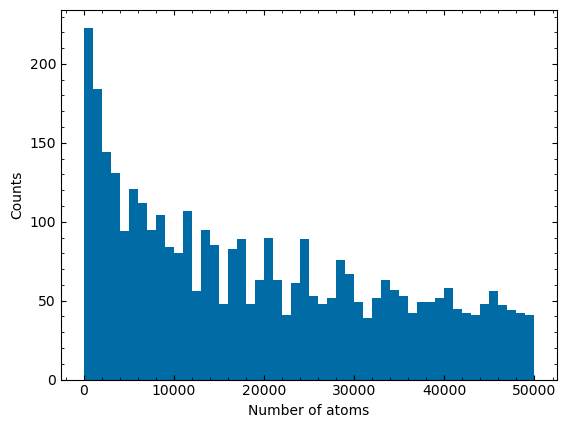

In [17]:
fig, ax = plt.subplots()
ax.hist(data["size"][:, 0], bins=np.arange(0, 50_001, 1000))
ax.set(xlabel="Number of atoms", ylabel="Counts")

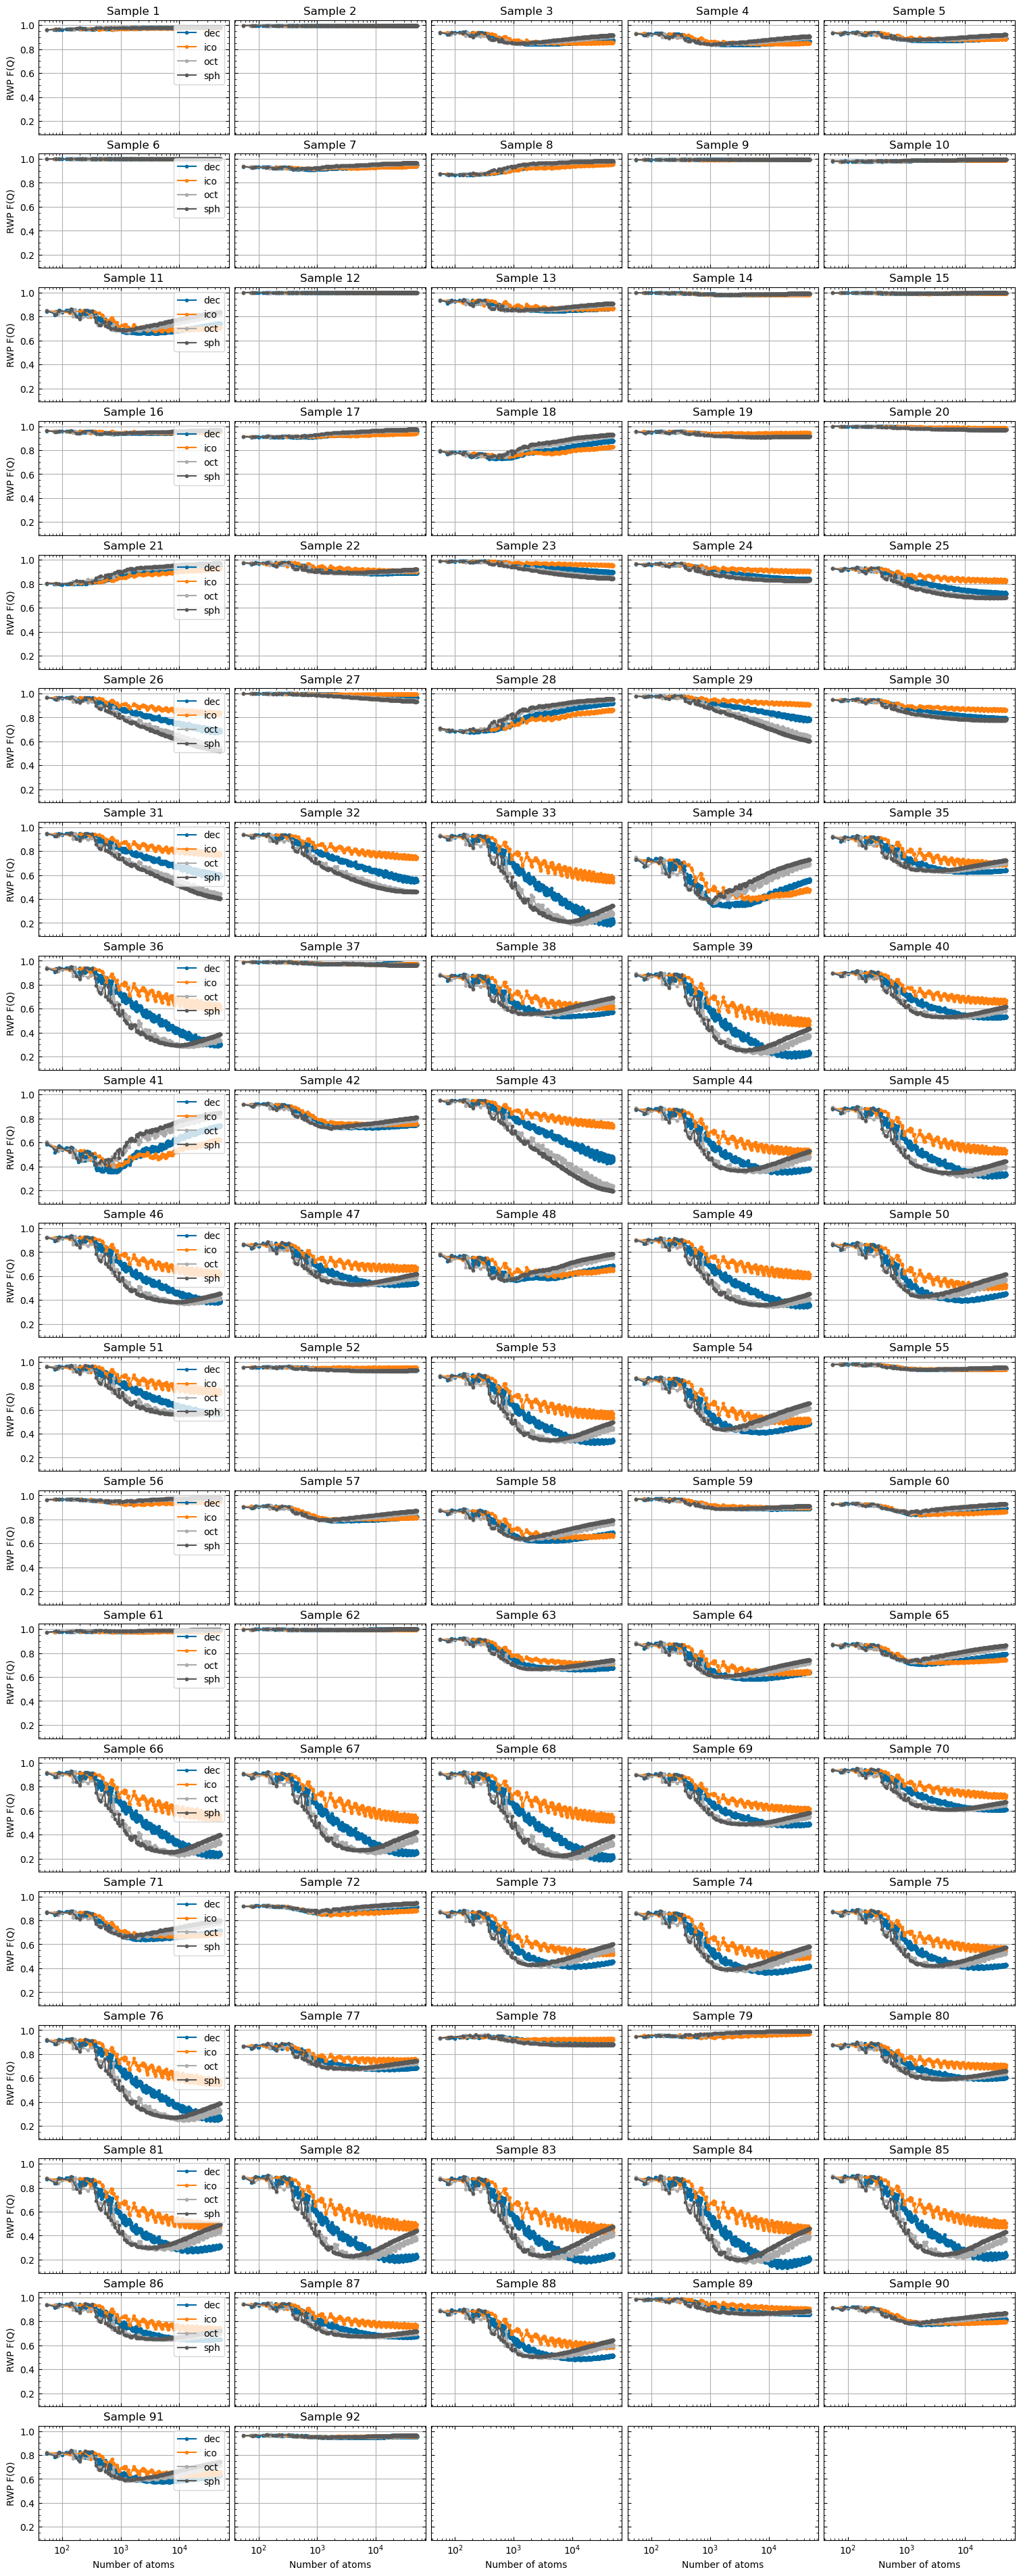

In [19]:
size = df["exp_sample"].iloc[-1]
ncols = 5
nrows = ceil(size / ncols)
fig, axs = plt.subplots(
    nrows,
    ncols,
    figsize=(3.0 * ncols, 2.0 * nrows),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
# axs[0, 0].set_yscale("log")
axs[0, 0].set_xscale("log")

for ax, (sample, group) in zip(axs.flat, df.groupby("exp_sample")):
    ax.set_title(f"Sample {sample}")
    for fam, group_fam in group.groupby("family"):
        group_fam.sort_values("size", inplace=True)
        ax.plot(group_fam["size"], group_fam["rwp_fq"], ".-", label=fam)
        ax.grid(True)
        ax.label_outer()
        if ax in axs[:, 0]:
            ax.legend(loc="upper right")
for ax in axs[:, 0]:
    ax.set(ylabel="RWP F(Q)")
for ax in axs[-1, :]:
    ax.set(xlabel="Number of atoms")

In [ ]:
def natoms_to_diameter(natoms):
    a = 0.03034479
    return (a * natoms) ** (1 / 3)


def diameter_to_natoms(diameter):
    a = 0.03034479
    return diameter**3 / a

In [14]:
test_exp_sample = 84

In [15]:
labels = dict(
    dec="Decahedra", oct="Octahedra", ico="Icosahedra", sph="Spheres"
)
colors = dict(oct="C1", sph="tab:green", dec="C0", ico="C2")

In [16]:
def plot_rwp(ax):
    fam_order = ["ico", "dec", "oct", "sph"]
    lines = {}
    for fam, group_fam in sorted(
        df[df.exp_sample == test_exp_sample].groupby("family"),
        key=lambda x: fam_order.index(x[0]),
    ):
        group_fam.sort_values("size", inplace=True)
        lines[fam] = ax.plot(
            group_fam["size"],
            group_fam["rwp_fq"],
            ".-",
            label=labels[fam],
            color=colors[fam],
            markersize=3,
            rasterized=True,
        )[0]
        min_idx = group_fam.rwp_fq.idxmin()
        ax.scatter(
            group_fam["size"].loc[min_idx],
            group_fam["rwp_fq"].loc[min_idx],
            marker="*",
            color=colors[fam],
            edgecolor="k",
            s=200,
            zorder=5,
        )
    # ax.axhline(
    #     df[df.exp_sample == test_exp_sample].rwp_fq.min() + 0.005,
    #     lw=1.0,
    #     color="k",
    #     ls="dashed",
    # )
    ax.grid(True)
    ax.minorticks_on()
    # ax.grid(True, which="minor", axis="y")
    ax.tick_params(axis="y", which="minor", right=True)
    label_order = ["sph", "oct", "dec", "ico"]
    legend = ax.legend(
        handles=[lines[fam] for fam in label_order],
        loc="lower left",
        markerscale=3,
    )
    ax.set(
        xlabel="Number of atoms",
        ylabel="$\\mathrm{R_{wp} \\left[F(Q)\\right]}$",
        xscale="log",
        # yscale="log",
        xlim=(30, 60_000),
        ylim=(0, 1.0),
    )

    ax.text(
        0.95,
        0.95,
        "MD",
        fontdict=dict(fontsize=14),
        transform=ax.transAxes,
        ha="right",
        va="top",
        bbox=dict(facecolor="white", edgecolor="none", pad=0.5, alpha=1.0),
    )

    diameters = [1, 2, 3, 4, 5, 6, 8, 10, 12]
    natoms = [diameter_to_natoms(d) for d in diameters]
    xlim = (natoms[0], natoms[-1])
    ax.set_xlim(xlim)
    twiny = ax.twiny()
    twiny.set(xlabel="Diameter [nm]", xscale="log", xlim=xlim)

    twiny.set_xticks(natoms, diameters)
    twiny.tick_params(axis="x", which="minor", top=False)
    return legend

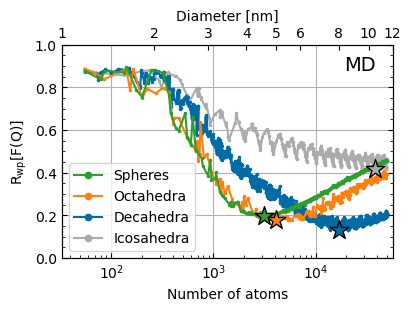

In [17]:
fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
legend = plot_rwp(ax)

In [111]:
fig.savefig("rwp_size_sample_84.pdf", dpi=100)

In [21]:
@cache
def get_simulated_scattering(sim_idx: int, exp_sample: int):
    assert sim_idx >= 0, sim_idx
    assert exp_sample > 0, exp_sample
    exp_idx = exp_sample - 1
    exp_scat = exp_data[exp_idx]
    _, _, fq, gr = get_all_from_iq_int(
        form_avg_sq=torch.from_numpy(data["form_avg_sq"]),
        size=data["size"][sim_idx, exp_idx],
        q=torch.from_numpy(data["q"]),
        iq_int=torch.from_numpy(data["iq_int"][sim_idx]),
        biso=data["biso"][sim_idx, exp_idx],
        qdamp=0.023,
        xscale=data["xscale"][sim_idx, exp_idx],
        q_ref=torch.from_numpy(exp_scat.q),
        r=torch.from_numpy(exp_scat.r),
    )
    yscale = data["yscale"][sim_idx, exp_idx]
    fq *= yscale
    gr *= yscale
    return ScatteringData(
        r=exp_scat.r, q=exp_scat.q, fq=fq.numpy(), gr=gr.numpy()
    )

In [31]:
# Pick samples to look at with MSE below a threshold
max_mse = 2e-3
interesting_samples = df[df.mse_fq < max_mse]["exp_sample"].unique()
interesting_samples

array([83, 84, 82, 39, 68, 85, 33, 66, 67, 76, 43])

In [32]:
fit_keys = ["xscale", "yscale", "biso"]

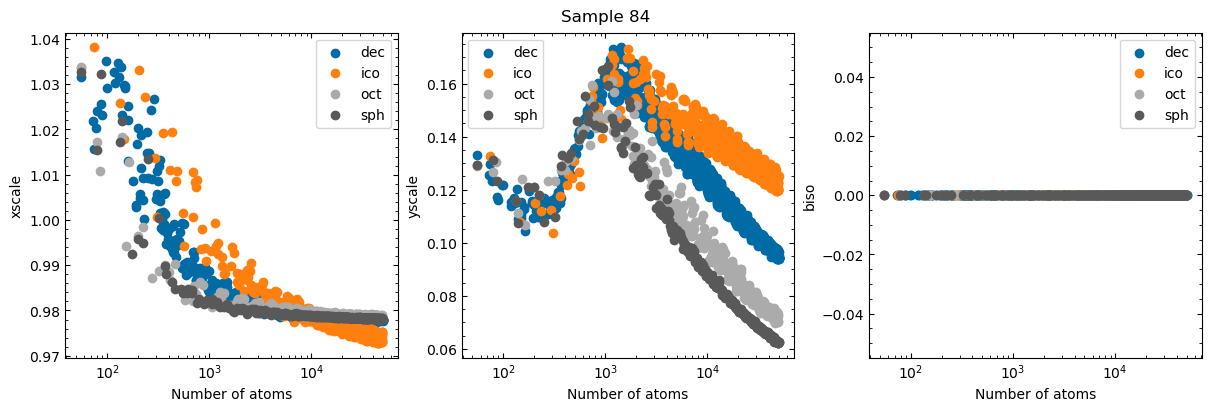

In [34]:
# B-iso vs number of atoms
fig, axs = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
fig.suptitle(f"Sample {test_exp_sample}")
for fam, group in df[df["exp_sample"] == test_exp_sample].groupby("family"):
    for k, ax in zip(fit_keys, axs):
        if k == "biso":
            xmask = group["size"]
        ax.scatter(group["size"], group[k], label=fam)
        ax.set(xlabel="Number of atoms", ylabel=k, xscale="log")
        ax.legend()

In [35]:
for idx in df[df["exp_sample"] == 84].groupby("family").mse_fq.idxmin():
    print(df.iloc[idx])
    print()

xscale             0.97871
rwp_fq             0.13227
yscale            0.115113
family                 dec
twin_111_ratio         0.0
mse_fq            0.000604
sim_idx                614
exp_sample              84
size                 16994
wulff                 True
max_miller             2.0
biso                   0.0
Name: 56571, dtype: object

xscale            0.976037
rwp_fq            0.416841
yscale             0.12285
family                 ico
twin_111_ratio         0.0
mse_fq            0.005996
sim_idx                136
exp_sample              84
size                 37995
wulff                 True
max_miller             1.0
biso                   0.0
Name: 12595, dtype: object

xscale            0.981199
rwp_fq             0.17672
yscale            0.115006
family                 oct
twin_111_ratio         NaN
mse_fq            0.001078
sim_idx                379
exp_sample              84
size                  4129
wulff                 True
max_miller             2.0

In [16]:
assert np.allclose(data["q_ref"], exp_data[test_exp_sample - 1].q)

In [ ]:
from itertools import chain


def plot_fq_res(ax, ax_res):
    fam_order = ["ico", "sph", "oct", "dec"]
    exp = ax.plot(
        exp_data[test_exp_sample - 1].q,
        exp_data[test_exp_sample - 1].fq,
        label="Experiment",
        color="k",
        lw=1.5,
    )
    lines = {}
    for fam, group in sorted(
        df[df.exp_sample == test_exp_sample].groupby("family"),
        key=lambda x: fam_order.index(x[0]),
    ):
        row_idx = group.mse_fq.idxmin()
        row = df.iloc[row_idx]
        print(row)
        print()
        # if fam in ("sph",):
        #     continue
        y = get_simulated_scattering(row.sim_idx, test_exp_sample).fq
        line = ax.plot(
            data["q_ref"],
            y,
            label=f"{labels[fam].replace('dra', 'dron').replace('res', 're')} ({row.rwp_fq:.2f})     ",
            color=colors[fam],
            lw=1.0,
            rasterized=True,
        )[0]
        lines[fam] = line
        # if fam != "ico" and fam != "sph":
        ax_res.plot(
            data["q_ref"],
            y - exp_data[test_exp_sample - 1].fq,
            color=line.get_color(),
            alpha=0.85,
            rasterized=True,
        )
    # ax.grid()
    ax.set(ylabel=r"$F(Q)$ [arb. unit]")
    ax_res.set(
        xlabel=r"$Q$ [$\mathrm{Å^{-1}}$]",
        ylabel=r"$F(Q) - F_\mathrm{exp}(Q)$ [arb. unit]",
        ylim=(-0.2, 0.2),
        xlim=(-0.25, 16.25),
    )
    ax_res.axhline(0, color="k", lw=1.0, zorder=0)
    label_order = ["sph", "oct", "dec", "ico"]
    leg = ax.legend(
        handles=[lines[fam] for fam in label_order],
        title="Morphology ($R_\\mathrm{wp}$)",
        loc="upper right",
        ncols=1,
        # bbox_to_anchor=[1.0, 0.85]
    )
    ax.add_artist(leg)
    leg_exp = ax.legend(
        handles=exp, loc="upper right", bbox_to_anchor=[1.0, 0.57]
    )
    fig.draw(fig.canvas.get_renderer())
    for text, line in zip(leg.get_texts(), leg.legend_handles):
        color = line.get_color()
        bbox = ax.transAxes.inverted().transform(text.get_window_extent())
        x = bbox[1, 0]
        x -= 0.02
        y = bbox[:, 1].mean()
        y += 0.035
        ax.scatter(
            [x],
            [y],
            marker="*",
            s=200,
            transform=ax.transAxes,
            facecolor=color,
            edgecolor="black",
            zorder=10,
        )
    for line in chain(leg.get_lines(), leg_exp.get_lines()):
        line.set_linewidth(2.0)
    return leg

max_miller             1.0
mse_fq            0.005996
yscale             0.12285
twin_111_ratio         0.0
biso                   0.0
sim_idx                136
rwp_fq            0.416841
xscale            0.976037
wulff                 True
family                 ico
exp_sample              84
size                 37995
Name: 12595, dtype: object

max_miller             NaN
mse_fq            0.001315
yscale            0.117998
twin_111_ratio         NaN
biso                   0.0
sim_idx               3333
rwp_fq             0.19522
xscale            0.979918
wulff                False
family                 sph
exp_sample              84
size                  3103
Name: 306719, dtype: object

max_miller             2.0
mse_fq            0.001078
yscale            0.115006
twin_111_ratio         NaN
biso                   0.0
sim_idx                379
rwp_fq             0.17672
xscale            0.981199
wulff                 True
family                 oct
exp_sample              8

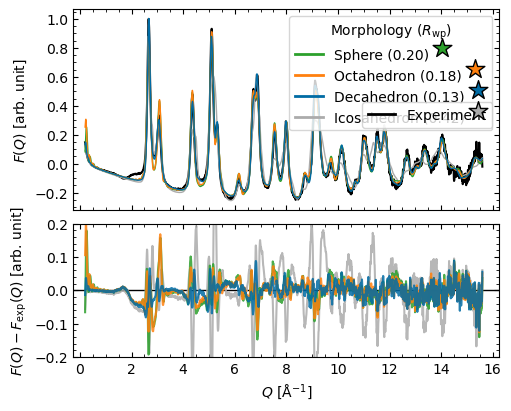

In [31]:
fig, (ax, ax_res) = plt.subplots(
    2,
    1,
    figsize=(5, 4),
    constrained_layout=True,
    sharex=True,
    height_ratios=[1.5, 1],
)
plot_fq_res(ax, ax_res)

# p = MarkerStyle("*", )
# ax.text(0, 0, r"$\star$", usetex=True, fontsize=40)

In [102]:
fig.savefig("fq_best_nps_sample_84.pdf", dpi=100)

In [24]:
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

In [ ]:
def load_nps():
    sim_idx_to_batch = pd.DataFrame(
        [[20, 0, 17], [46, 1, 12], [58, 0, 26], [45, 0, 6]],
        index=pd.Index([614, 379, 136, 3333], name="sim_idx"),
        columns=["batch", "mpi_rank", "batch_idx"],
    )
    images = [
        read(
            f"../../relax/relax/{row['batch']}/{row['mpi_rank']}_0.001.traj",
            index=row["batch_idx"],
        )
        for sim_idx in sim_idx_to_batch.index
        if (row := sim_idx_to_batch.loc[sim_idx]).name == sim_idx
    ]
    ico = images[2]
    # Align a corner atom with the z direction (index found through GUI)
    ico.rotate(ico.positions[37817], "z", center="COP")
    # Align another corner with the -y direction (rotation about z)
    y_direction = ico.positions[37949] - ico.positions[37817]
    y_direction[2] = 0
    ico.rotate(y_direction, "-y", center="COP")
    return images


def plot_strained_nps(ax: Axes):
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    from PIL import Image

    images = load_nps()

    placements = {
        "dec": (0, 0),
        "ico": (150, 50),
        "sph": (0, 0),
        "oct": (0, 0),
    }
    text_placements = {
        "dec": (0, 0),
        "ico": (0, 40),
        "sph": (0, 0),
        "oct": (0, 0),
    }
    fam_order = ["sph", "oct", "dec", "ico"]
    fam_names = {
        "sph": "Sphere",
        "oct": "Octa-\nhedron",
        "dec": "Decahedron",
        "ico": "Icosahedron",
    }
    arrays = [
        np.asarray(Image.open(f"ovito/figure_{atoms.info['sim_idx']}.png"))
        for fam in fam_order
        for atoms in images
        if atoms.info["family"] == fam
    ]
    height = max([x.shape[0] for x in arrays]) + 50
    widths = [x.shape[1] for x in arrays]
    spacing = 20
    width = sum(widths) + spacing * (len(widths) - 1)
    array = np.zeros_like(arrays[0], shape=(height, width, 4))
    offset = 0
    centers = []
    tops = []
    for arr in arrays:
        array[-arr.shape[0] :, offset : offset + arr.shape[1]] = arr
        centers.append(offset + arr.shape[1] / 2)
        tops.append(height - np.nonzero(arr[:, :, 3])[0].max())
        offset += arr.shape[1] + spacing
    # print(tops)
    ax.imshow(array, aspect="equal")
    # ax.scatter(centers, tops, color="red")
    ax.set_axis_off()

    for fam, x, y in zip(fam_order, centers, tops):
        ax.text(
            x + text_placements[fam][0],
            y - 70 + text_placements[fam][1],
            fam_names[fam],
            ha="center",
            va="bottom",
            # fontsize=10,
        )
        ax.scatter(
            x + placements[fam][0],
            y - 40 + placements[fam][1],
            marker="*",
            s=200,
            facecolor=colors[fam],
            edgecolor="black",
            zorder=10,
        )

    axins = ax.inset_axes(
        bounds=[0.15, 1.0, 0.2, 0.05],
        transform=ax.transAxes,
    )
    axins.xaxis.set_ticks_position("bottom")

    norm = Normalize(vmin=-0.05, vmax=0.05, clip=True)
    sm = ScalarMappable(norm=norm, cmap="bwr")
    cbar = fig.colorbar(
        sm, cax=axins, orientation="horizontal", location="bottom"
    )
    # cbar = plt.colorbar(sm, cax=ax_cbar, orientation="horizontal")
    cbar.set_label("Strain", labelpad=0)
    cbar.set_ticks(
        [-0.05, 0, 0.05],
        labels=["\N{MINUS SIGN}5%", "0", "\N{PLUS SIGN}5%"],
        # fontsize=10,
    )
    cbar.minorticks_off()

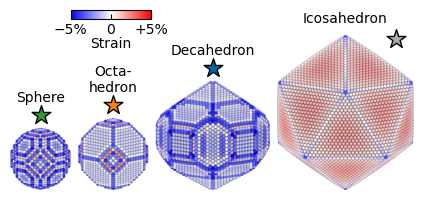

In [26]:
fig, ax = plt.subplots(
    figsize=(10 * 0.7 / 1.7, 5 * 1 / 2.5), constrained_layout=True
)
plot_strained_nps(ax)

In [27]:
from typing import Literal


def get_figure_label_generator(loc: Literal["top", "bottom"] = "top"):
    # fig_labels = get_figure_label_generator()
    # for ax in axs:
    #     ax.text(**next(fig_labels), transform=ax.transAxes)
    letters = "abcdefghijklmn"
    out = {
        "x": 0,
        "y": 1.0 if loc == "top" else 0.03,
        "ha": "left",
        "va": "top" if loc == "top" else "bottom",
        "fontweight": "normal",
        "fontsize": 20,
        "color": "k",
    }
    for letter in letters:
        out["s"] = f"{letter})"
        yield out

In [28]:
plt.rcParams["text.usetex"] = False
plt.rcParams["font.family"] = "sans-serif"

max_miller             1.0
mse_fq            0.005996
yscale             0.12285
twin_111_ratio         0.0
biso                   0.0
sim_idx                136
rwp_fq            0.416841
xscale            0.976037
wulff                 True
family                 ico
exp_sample              84
size                 37995
Name: 12595, dtype: object

max_miller             NaN
mse_fq            0.001315
yscale            0.117998
twin_111_ratio         NaN
biso                   0.0
sim_idx               3333
rwp_fq             0.19522
xscale            0.979918
wulff                False
family                 sph
exp_sample              84
size                  3103
Name: 306719, dtype: object

max_miller             2.0
mse_fq            0.001078
yscale            0.115006
twin_111_ratio         NaN
biso                   0.0
sim_idx                379
rwp_fq             0.17672
xscale            0.981199
wulff                 True
family                 oct
exp_sample              8

Text(0, 1.0, 'c)')

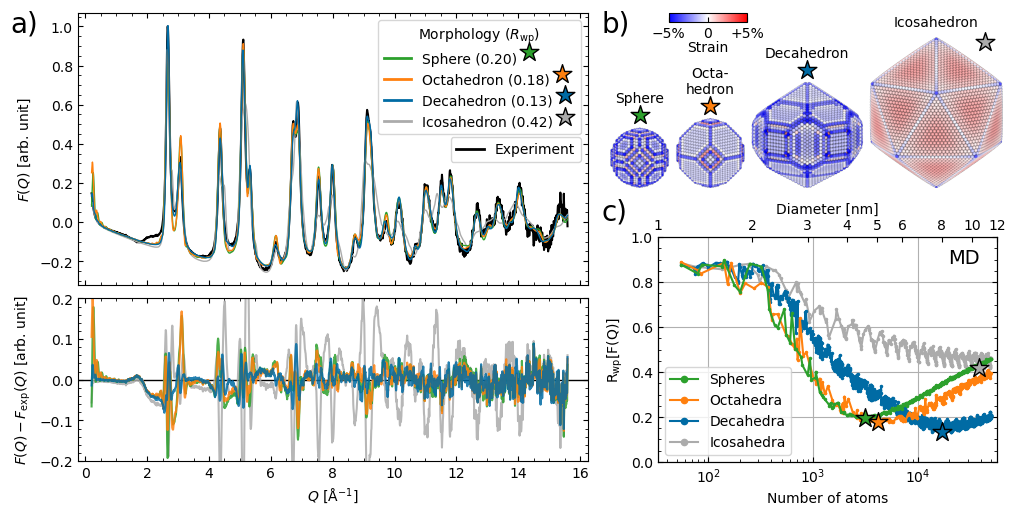

In [32]:
fig = plt.figure(figsize=(10, 5), constrained_layout=True)
gs_left_right = GridSpec(1, 3, figure=fig, width_ratios=[1, 0.015, 0.7])
gs_fq = GridSpecFromSubplotSpec(
    2, 1, subplot_spec=gs_left_right[0], height_ratios=[5, 3]
)
gs_right = GridSpecFromSubplotSpec(
    2, 1, subplot_spec=gs_left_right[2], height_ratios=[1, 1.7]
)
gs_nps = gs_right[0]
gs_rwp = gs_right[1]

fig_rwp = fig.add_subfigure(gs_rwp)
ax_rwp = fig_rwp.add_subplot()
plot_rwp(ax_rwp)

fig_nps = fig.add_subfigure(gs_nps)
ax_nps = fig_nps.add_subplot()
plot_strained_nps(ax_nps)

ax_fq = fig.add_subplot(gs_fq[0])
ax_fq_res = fig.add_subplot(gs_fq[1], sharex=ax_fq)
leg_fq = plot_fq_res(ax_fq, ax_fq_res)
ax_fq.tick_params(axis="x", labelbottom=False)

fig_labels = get_figure_label_generator()
fig.text(**next(fig_labels))
fig_nps.text(**next(fig_labels))
fig_rwp.text(**next(fig_labels))

In [33]:
fig.savefig("fq_best_nps_md_rasterized.pdf", dpi=300)